In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install -q mtcnn opencv-python-headless

import os
import shutil
import cv2
from mtcnn import MTCNN

carpeta_origen = "/content/drive/MyDrive/fotos_crudas"
carpeta_destino = "/content/drive/MyDrive/dataset_facial_7fotos"
os.makedirs(carpeta_destino, exist_ok=True)

detector = MTCNN()

for archivo in os.listdir(carpeta_origen):
    ruta_img = os.path.join(carpeta_origen, archivo)
    img = cv2.imread(ruta_img)
    if img is None:
        continue

    # MTCNN requiere formato RGB
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    resultados = detector.detect_faces(img_rgb)

    if len(resultados) > 0:
        x, y, w, h = resultados[0]['box']
        # Evitar coordenadas negativas si el rostro está muy cerca del borde
        x, y = max(0, x), max(0, y)

        rostro_recortado = img[y:y+h, x:x+w]
        rostro_final = cv2.resize(rostro_recortado, (224, 224))

        nombre_salida = os.path.splitext(archivo)[0] + ".jpg"
        cv2.imwrite(os.path.join(carpeta_destino, nombre_salida), rostro_final)
        print(f"Procesada correctamente: {nombre_salida}")
    else:
        print(f"No se detectó rostro en: {archivo}")

shutil.make_archive("/content/drive/MyDrive/dataset_7fotos", 'zip', carpeta_destino)
print("¡Listo! Revisa tu Google Drive.")

Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.


Procesada correctamente: Integrante_1.jpg
Procesada correctamente: Famoso_5.jpg
Procesada correctamente: Famoso_4.jpg
Procesada correctamente: Famoso_1.jpg
Procesada correctamente: Famoso_3.jpg
Procesada correctamente: Famoso_2.jpg
Procesada correctamente: Integrante_2.jpg
¡Listo! Revisa tu Google Drive.


In [3]:
import os
import cv2
import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator

carpeta_7fotos = "/content/drive/MyDrive/dataset_facial_7fotos"
carpeta_dataset_cnn = "/content/drive/MyDrive/dataset_cnn_completo"

# Verificar que Drive esté conectado y la carpeta exista
if not os.path.exists("/content/drive/MyDrive"):
    print("⚠️ Error: Google Drive no está montado. Ejecuta primero la Celda 1.")
elif not os.path.exists(carpeta_7fotos):
    print("⚠️ No se encontró 'dataset_facial_7fotos'. Estas son las carpetas en tu Drive:")
    print(os.listdir("/content/drive/MyDrive"))
else:
    generador = ImageDataGenerator(
        rotation_range=15,
        width_shift_range=0.1,
        height_shift_range=0.1,
        zoom_range=0.15,
        horizontal_flip=True,
        brightness_range=[0.75, 1.25],
        fill_mode='nearest'
    )

    for archivo in os.listdir(carpeta_7fotos):
        if not archivo.lower().endswith(('.jpg', '.jpeg', '.png')):
            continue
        nombre_clase = os.path.splitext(archivo)[0]
        ruta_clase = os.path.join(carpeta_dataset_cnn, nombre_clase)
        os.makedirs(ruta_clase, exist_ok=True)

        img = cv2.imread(os.path.join(carpeta_7fotos, archivo))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_array = np.expand_dims(img, 0)

        cv2.imwrite(os.path.join(ruta_clase, f"{nombre_clase}_0.jpg"), cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
        i = 1
        for batch in generador.flow(img_array, batch_size=1):
            img_aug = batch[0].astype(np.uint8)
            cv2.imwrite(os.path.join(ruta_clase, f"{nombre_clase}_{i}.jpg"), cv2.cvtColor(img_aug, cv2.COLOR_RGB2BGR))
            i += 1
            if i >= 40:
                break

    print("¡Dataset expandido a 40 imágenes por persona (280 en total)!")

¡Dataset expandido a 40 imágenes por persona (280 en total)!


Found 224 images belonging to 7 classes.
Found 56 images belonging to 7 classes.
Clases guardadas: {0: 'Famoso_1', 1: 'Famoso_2', 2: 'Famoso_3', 3: 'Famoso_4', 4: 'Famoso_5', 5: 'Integrante_1', 6: 'Integrante_2'}
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/25
14/14 ━━━━━━━━━━━━━━━━━━━━ 28s 2s/step - accuracy: 0.7277 - loss: 0.8136 - val_accuracy: 0.8929 - val_loss: 0.4087
Epoch 2/25
14/14 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.9955 - loss: 0.0317 - val_accuracy: 0.9643 - val_loss: 0.2102
Epoch 3/25
14/14 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.9955 - loss: 0.0199 - val_accuracy: 1.0000 - val_loss: 0.1151
Epoch 4/25
14/14 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 1.0000 - loss: 0.0086 - val_accuracy: 1.0000 - val_loss: 0.0693
Epoch 5/25
14/14 ━━━━━━━━━━━━━━━━━━━━ 24s 2s/step - accuracy: 1.0000 - loss: 0.0057 - val_accuracy: 1.0000 - val_loss: 0.0475
Epoch 6/25
14/14 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 1.0000 - loss: 0.0103 - val_accuracy: 1.0000 -

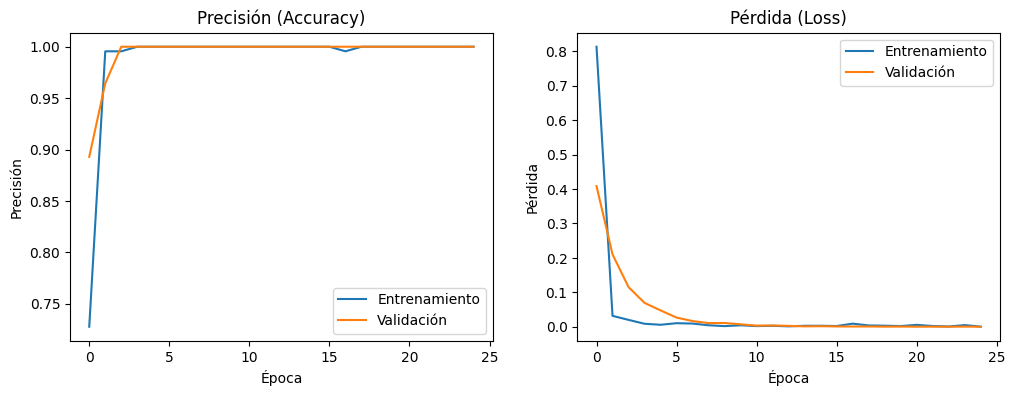

In [4]:
import json
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
RUTA_DATASET = "/content/drive/MyDrive/dataset_cnn_completo"

# 1. Preprocesamiento, Normalización [0, 1] y División 80% Entrenamiento / 20% Validación
datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True,
    validation_split=0.2
)

train_gen = datagen.flow_from_directory(
    RUTA_DATASET,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training'
)

val_gen = datagen.flow_from_directory(
    RUTA_DATASET,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation'
)

# Guardar las etiquetas de las 7 clases
clases = {v: k for k, v in train_gen.class_indices.items()}
with open("/content/drive/MyDrive/clases.json", "w") as f:
    json.dump(clases, f)
print("Clases guardadas:", clases)

# 2. Arquitectura CNN (Transfer Learning con MobileNetV2 + Regularización)
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.4)(x)
salidas = Dense(len(clases), activation='softmax')(x)

modelo = Model(inputs=base_model.input, outputs=salidas)
modelo.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 3. Callbacks para guardar el mejor modelo
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ModelCheckpoint("/content/drive/MyDrive/modelo_facial.keras", monitor='val_accuracy', save_best_only=True)
]

# 4. Entrenamiento
historial = modelo.fit(
    train_gen,
    validation_data=val_gen,
    epochs=25,
    callbacks=callbacks
)

# 5. Gráficas de Precisión y Pérdida
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(historial.history['accuracy'], label='Entrenamiento')
plt.plot(historial.history['val_accuracy'], label='Validación')
plt.title('Precisión (Accuracy)')
plt.xlabel('Época')
plt.ylabel('Precisión')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(historial.history['loss'], label='Entrenamiento')
plt.plot(historial.history['val_loss'], label='Validación')
plt.title('Pérdida (Loss)')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()
plt.show()